<a href="https://colab.research.google.com/github/SaahirNagpal/neetcode-submissions/blob/main/vegetable_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vegetable Price Prediction using Linear Regression
**Data:** Government mandi price records (Agmarknet / data.gov.in)
**Goal:** Predict the *modal price* (Rs/quintal) of a vegetable in a mandi from its recent price history, market arrivals and seasonality.

**Pipeline:** Load data → Clean → EDA → Feature engineering → Time-based split → Linear Regression (+ Ridge, + naive baseline) → Evaluation → Save model

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Get the data

Pick **one** option by setting `DATA_SOURCE`:

| Option | What it does |
|---|---|
| `"csv"` | Upload a CSV you downloaded from **Agmarknet** (agmarknet.gov.in → *Price and Arrivals* → export) or from **data.gov.in** ("Current Daily Price of Various Commodities from Various Markets (Mandis)"). **Recommended for real history.** |
| `"api"` | Pull records from the data.gov.in API using your free API key. Note: this API mostly returns *recent/current-day* records, so run it daily and accumulate, or use a CSV for long history. |
| `"synthetic"` | Generates realistic *fake* mandi-style data (seasonality + trend + noise) so the notebook runs end-to-end for testing. **Not real data.** |

Expected columns (names are matched loosely): `state, district, market, commodity, variety, date, min_price, max_price, modal_price` and optionally `arrivals` (tonnes).

In [4]:
DATA_SOURCE = "csv"

API_KEY = "PASTE_YOUR_DATA_GOV_IN_API_KEY"
RESOURCE_ID = "9ef84268-d588-465a-a308-a864a43d0070"
COMMODITIES = ["Tomato", "Onion", "Potato"]

In [5]:
def load_csv():
    from google.colab import files
    up = files.upload()
    name = list(up.keys())[0]
    return pd.read_csv(name)

def load_api(pages=10, limit=1000):
    import requests
    frames = []
    for c in COMMODITIES:
        for p in range(pages):
            url = (f"https://api.data.gov.in/resource/{RESOURCE_ID}"
                   f"?api-key={API_KEY}&format=json&limit={limit}&offset={p*limit}"
                   f"&filters[commodity]={c}")
            r = requests.get(url, timeout=60)
            r.raise_for_status()
            recs = r.json().get("records", [])
            if not recs:
                break
            frames.append(pd.DataFrame(recs))
    return pd.concat(frames, ignore_index=True)

def make_synthetic(seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
    base = {"Tomato": 2200, "Onion": 1800, "Potato": 1400}
    amp = {"Tomato": 0.35, "Onion": 0.30, "Potato": 0.15}
    peak_doy = {"Tomato": 200, "Onion": 290, "Potato": 330}
    markets = [("Maharashtra", "Pune", "Pune"), ("Delhi", "Delhi", "Azadpur"),
               ("Karnataka", "Bangalore", "Bangalore")]
    rows = []
    t = np.arange(len(dates))
    doy = dates.dayofyear.values
    for com, b in base.items():
        season = amp[com] * np.cos(2 * np.pi * (doy - peak_doy[com]) / 365.25)
        trend = 1 + 0.0002 * t
        for st, di, mk in markets:
            mk_off = rng.normal(1.0, 0.05)
            shock = np.cumsum(rng.normal(0, 0.012, len(dates)))
            shock -= np.convolve(shock, np.ones(60) / 60, mode="same")  # mean-revert
            price = b * mk_off * trend * (1 + season) * np.exp(shock)
            price = np.clip(price, 300, None)
            arrivals = 120 * (1 + 0.4 * np.cos(2 * np.pi * (doy - peak_doy[com] + 90) / 365.25)) \
                       * (b / price) ** 0.5 * rng.lognormal(0, 0.15, len(dates))
            mn = price * rng.uniform(0.85, 0.97, len(dates))
            mx = price * rng.uniform(1.03, 1.15, len(dates))
            rows.append(pd.DataFrame({"state": st, "district": di, "market": mk, "commodity": com,
                                      "date": dates, "min_price": mn, "max_price": mx,
                                      "modal_price": price, "arrivals": arrivals}))
    return pd.concat(rows, ignore_index=True)

if DATA_SOURCE == "csv":
    raw = load_csv()
elif DATA_SOURCE == "api":
    raw = load_api()
else:
    raw = make_synthetic()
    print("⚠️ Using SYNTHETIC data (for pipeline testing only).")

print(raw.shape)
raw.head()

Saving mandi_prices_dataset.csv to mandi_prices_dataset.csv
(35075, 10)


,State,District,Market,Commodity,Variety,Arrival_Date,Min Price,Max Price,Modal Price,Arrivals_in_Tonnes
0,Maharashtra,Pune,Pune,Tomato,Hybrid,01/01/2022,1329.0,1612.0,1510.0,102.1
1,Maharashtra,Pune,Pune,Tomato,Hybrid,02/01/2022,1348.0,1731.0,1516.0,115.7
2,Maharashtra,Pune,Pune,Tomato,Hybrid,03/01/2022,1391.0,1663.0,1512.0,138.7
3,Maharashtra,Pune,Pune,Tomato,Hybrid,04/01/2022,1339.0,1645.0,1498.0,135.3
4,Maharashtra,Pune,Pune,Tomato,Hybrid,05/01/2022,1288.0,1576.0,1492.0,158.2


## 3. Clean & standardise
Normalise column names, parse dates, convert prices to numbers, drop invalid rows and collapse duplicates to one row per (commodity, market, date).

In [6]:
df = raw.copy()
df.columns = [c.strip().lower().replace(" ", "_").replace("(rs./quintal)", "").strip("_") for c in df.columns]

# loose column matching for real-world files
rename = {}
for c in df.columns:
    if "modal" in c: rename[c] = "modal_price"
    elif c.startswith("min") and "price" in c: rename[c] = "min_price"
    elif c.startswith("max") and "price" in c: rename[c] = "max_price"
    elif "date" in c: rename[c] = "date"
    elif c in ("arrival", "arrivals", "arrivals_in_tonnes", "arrival_quantity"): rename[c] = "arrivals"
df = df.rename(columns=rename)

required = ["commodity", "market", "date", "modal_price"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing required columns: {missing}. Found: {list(df.columns)}"

df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
for c in ["min_price", "max_price", "modal_price", "arrivals"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# fall back if min/max missing
if "min_price" not in df.columns: df["min_price"] = df["modal_price"]
if "max_price" not in df.columns: df["max_price"] = df["modal_price"]
HAS_ARRIVALS = "arrivals" in df.columns and df["arrivals"].notna().mean() > 0.5

df = df.dropna(subset=["date", "modal_price"])
df = df[df["modal_price"] > 0]

agg = {"min_price": "mean", "max_price": "mean", "modal_price": "mean"}
if HAS_ARRIVALS: agg["arrivals"] = "mean"
df = (df.groupby(["commodity", "market", "date"], as_index=False).agg(agg)
        .sort_values(["commodity", "market", "date"]).reset_index(drop=True))

# keep only series with enough history
counts = df.groupby(["commodity", "market"]).size()
keep = counts[counts >= 60].index
df = df.set_index(["commodity", "market"]).loc[keep].reset_index()

print(df.shape, "| arrivals used:", HAS_ARRIVALS)
print(df["commodity"].value_counts())
df.describe()

(35075, 7) | arrivals used: True
commodity
Brinjal        7015
Cauliflower    7015
Onion          7015
Potato         7015
Tomato         7015
Name: count, dtype: int64


,date,min_price,max_price,modal_price,arrivals
count,35075,35075.000000,35075.000000,35075.000000,35075.000000
mean,2024-01-01 08:18:34.229508352,2014.007071,2412.179216,2213.485046,115.279276
min,2022-01-01 00:00:00,942.000000,1164.000000,1097.000000,36.800000
25%,2023-01-01 00:00:00,1527.000000,1828.000000,1680.000000,81.100000
50%,2024-01-02 00:00:00,1872.000000,2238.000000,2055.000000,111.500000
75%,2024-12-31 00:00:00,2410.000000,2884.000000,2643.000000,144.800000
max,2025-12-31 00:00:00,5407.000000,6328.000000,5717.000000,307.700000
std,NaN,616.027589,736.016482,671.875862,39.580836


## 4. Exploratory data analysis

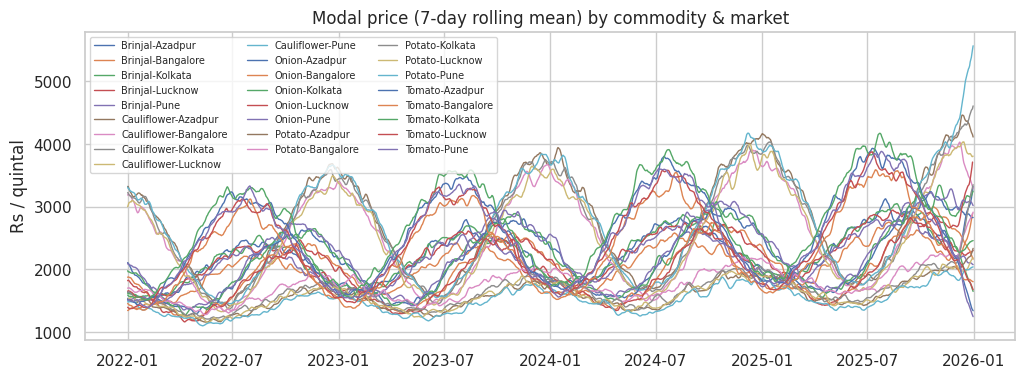

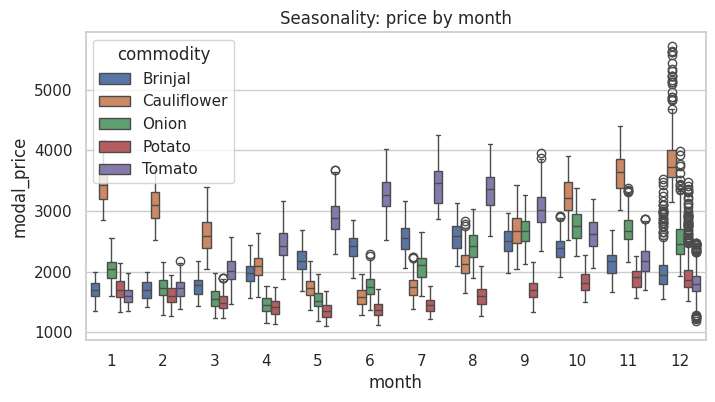

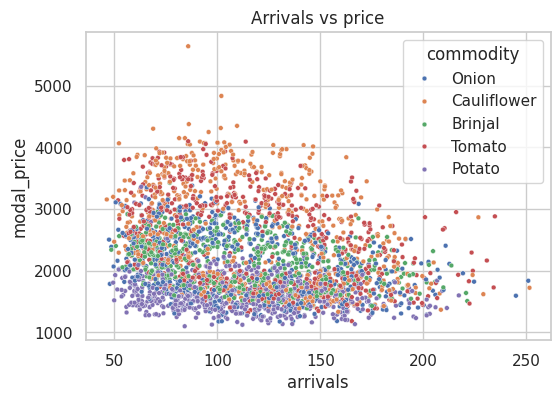

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
for (com, mk), g in df.groupby(["commodity", "market"]):
    ax.plot(g["date"], g["modal_price"].rolling(7, min_periods=1).mean(), label=f"{com}-{mk}", lw=1)
ax.set_title("Modal price (7-day rolling mean) by commodity & market")
ax.set_ylabel("Rs / quintal")
ax.legend(ncol=3, fontsize=7)
plt.show()

df["month"] = df["date"].dt.month
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="month", y="modal_price", hue="commodity")
plt.title("Seasonality: price by month")
plt.show()

if HAS_ARRIVALS:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=0), x="arrivals", y="modal_price", hue="commodity", s=12)
    plt.title("Arrivals vs price")
    plt.show()

## 5. Feature engineering
Everything is built **only from past information** (shifted by 1 day) so there is no data leakage:
- lag prices (1, 7, 14 days), rolling mean/std of the last 7 and 30 days
- previous day's min–max spread (volatility proxy)
- previous day's arrivals (supply), if available
- seasonality: month, day-of-week, sin/cos of day-of-year
- categorical: commodity, market (one-hot)

In [8]:
def build_features(d):
    d = d.sort_values(["commodity", "market", "date"]).copy()
    g = d.groupby(["commodity", "market"], group_keys=False)

    d["lag_1"] = g["modal_price"].shift(1)
    d["lag_7"] = g["modal_price"].shift(7)
    d["lag_14"] = g["modal_price"].shift(14)
    d["roll_mean_7"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(7).mean())
    d["roll_std_7"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(7).std())
    d["roll_mean_30"] = g["modal_price"].transform(lambda s: s.shift(1).rolling(30).mean())
    d["spread_lag1"] = (d["max_price"] - d["min_price"]).groupby([d["commodity"], d["market"]]).shift(1)
    if HAS_ARRIVALS:
        d["arrivals_lag1"] = g["arrivals"].shift(1)
        d["arrivals_roll7"] = g["arrivals"].transform(lambda s: s.shift(1).rolling(7).mean())

    d["month"] = d["date"].dt.month
    d["dayofweek"] = d["date"].dt.dayofweek
    doy = d["date"].dt.dayofyear
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    return d.dropna().reset_index(drop=True)

feat = build_features(df)

num_cols = ["lag_1", "lag_7", "lag_14", "roll_mean_7", "roll_std_7", "roll_mean_30",
            "spread_lag1", "doy_sin", "doy_cos"]
if HAS_ARRIVALS:
    num_cols += ["arrivals_lag1", "arrivals_roll7"]
cat_cols = ["commodity", "market"]
TARGET = "modal_price"

print(feat.shape)
feat[["date", "commodity", "market", TARGET] + num_cols].head()

(34325, 20)


,date,commodity,market,modal_price,lag_1,lag_7,lag_14,roll_mean_7,roll_std_7,roll_mean_30,spread_lag1,doy_sin,doy_cos,arrivals_lag1,arrivals_roll7
0,2022-02-01,Brinjal,Azadpur,1509.0,1529.0,1528.0,1580.0,1545.571429,16.880533,1575.733333,331.0,0.523094,0.852275,136.4,123.628571
1,2022-02-02,Brinjal,Azadpur,1498.0,1509.0,1534.0,1576.0,1542.857143,21.161510,1571.466667,256.0,0.537677,0.843151,118.2,123.500000
2,2022-02-03,Brinjal,Azadpur,1509.0,1498.0,1545.0,1564.0,1537.714286,27.188933,1566.733333,292.0,0.552101,0.833777,93.8,122.900000
3,2022-02-04,Brinjal,Azadpur,1536.0,1509.0,1574.0,1545.0,1532.571429,28.930129,1562.800000,245.0,0.566362,0.824157,130.3,124.814286
4,2022-02-05,Brinjal,Azadpur,1547.0,1536.0,1558.0,1543.0,1527.142857,22.770072,1559.833333,304.0,0.580455,0.814292,108.7,120.400000


## 6. Time-based train / test split
We never shuffle time series: train on the earlier 80% of dates and test on the most recent 20%.

In [9]:
cutoff = feat["date"].quantile(0.80)
train = feat[feat["date"] <= cutoff]
test = feat[feat["date"] > cutoff]
print("Train:", train["date"].min().date(), "→", train["date"].max().date(), len(train))
print("Test :", test["date"].min().date(), "→", test["date"].max().date(), len(test))

X_train, y_train = train[num_cols + cat_cols], train[TARGET]
X_test, y_test = test[num_cols + cat_cols], test[TARGET]

Train: 2022-01-31 → 2025-03-21 27483
Test : 2025-03-22 → 2025-12-31 6842


## 7. Train models
We compare a **naive baseline** (tomorrow's price = today's price), **Linear Regression** (the main model) and **Ridge** (regularised linear regression).

In [10]:
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "Linear Regression": Pipeline([("pre", pre), ("model", LinearRegression())]),
    "Ridge (alpha=10)": Pipeline([("pre", pre), ("model", Ridge(alpha=10))]),
}

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE %": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "R2": r2_score(y_true, y_pred),
    }

results = {"Naive (yesterday's price)": metrics(y_test, X_test["lag_1"])}
preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
    results[name] = metrics(y_test, preds[name])

pd.DataFrame(results).T.round(3)

,MAE,RMSE,MAPE %,R2
Naive (yesterday's price),26.019,34.465,1.035,0.998
Linear Regression,25.172,33.429,1.001,0.998
Ridge (alpha=10),25.634,34.144,1.019,0.998


## 8. Diagnostics

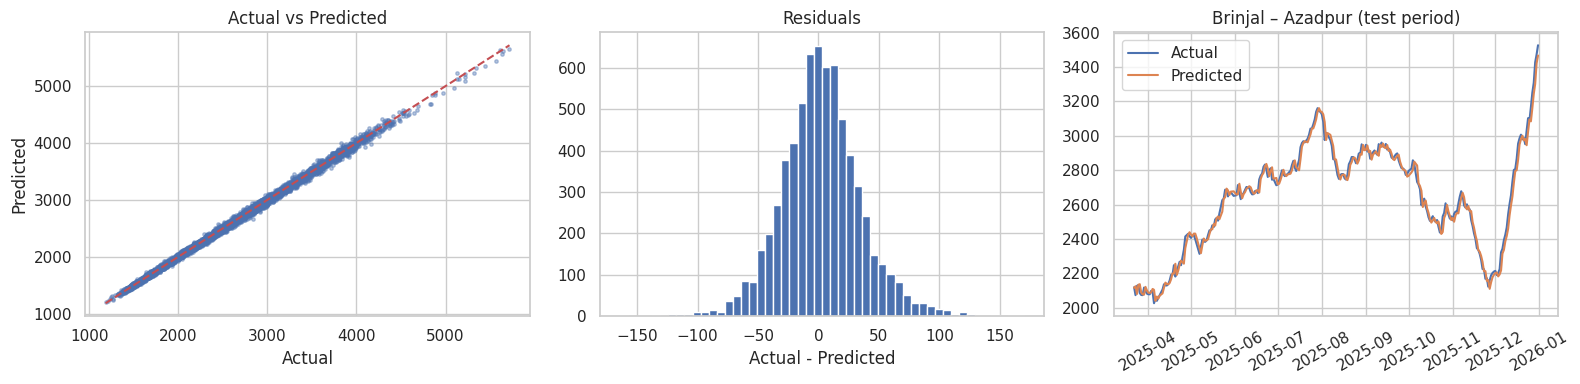

In [11]:
best = "Linear Regression"
y_pred = preds[best]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(y_test, y_pred, s=6, alpha=0.4)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--")
axes[0].set(title="Actual vs Predicted", xlabel="Actual", ylabel="Predicted")

res = y_test - y_pred
axes[1].hist(res, bins=50)
axes[1].set(title="Residuals", xlabel="Actual - Predicted")

one = test.assign(pred=y_pred)
one = one[(one["commodity"] == one["commodity"].iloc[0]) & (one["market"] == one["market"].iloc[0])]
axes[2].plot(one["date"], one[TARGET], label="Actual")
axes[2].plot(one["date"], one["pred"], label="Predicted")
axes[2].set_title(f"{one['commodity'].iloc[0]} – {one['market'].iloc[0]} (test period)")
axes[2].legend()
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

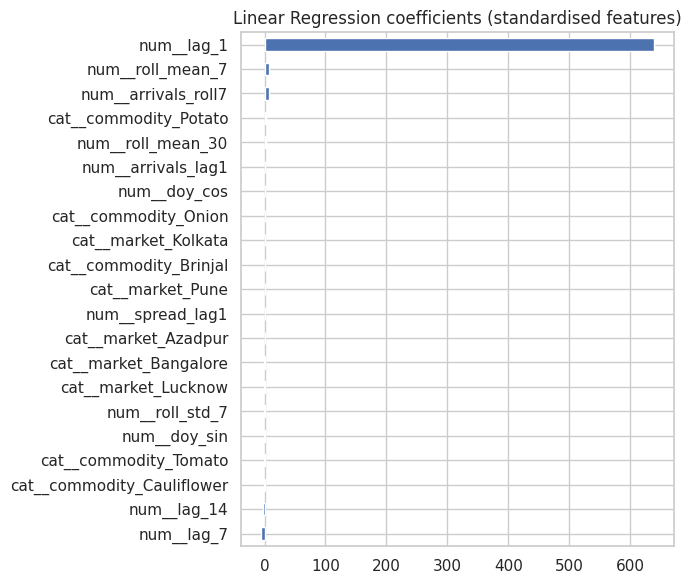

In [12]:
lin = models[best]
names = lin.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lin.named_steps["model"].coef_, index=names).sort_values()
plt.figure(figsize=(7, 6))
coefs.plot(kind="barh")
plt.title("Linear Regression coefficients (standardised features)")
plt.tight_layout()
plt.show()

## 9. Predict & save

In [13]:
joblib.dump(models[best], "veg_price_linreg.joblib")

# Example: predict for the last available row of each series (i.e. a "next-day style" prediction)
latest = feat.sort_values("date").groupby(["commodity", "market"]).tail(1)
latest = latest.assign(predicted_modal_price=models[best].predict(latest[num_cols + cat_cols]))
latest[["date", "commodity", "market", "modal_price", "predicted_modal_price"]].round(1)

,date,commodity,market,modal_price,predicted_modal_price
19221,2025-12-30,Onion,Lucknow,3981.0,3912.6
2745,2025-12-30,Brinjal,Bangalore,3092.0,2992.7
13729,2025-12-31,Cauliflower,Pune,5717.0,5643.7
15102,2025-12-31,Onion,Azadpur,2843.0,2836.8
17848,2025-12-31,Onion,Kolkata,3354.0,3320.9
20594,2025-12-31,Onion,Pune,2924.0,2959.3
12356,2025-12-31,Cauliflower,Lucknow,3901.0,3834.4
21967,2025-12-31,Potato,Azadpur,2418.0,2439.6
24713,2025-12-31,Potato,Kolkata,3469.0,3407.9
23340,2025-12-31,Potato,Bangalore,2993.0,2914.8


## 10. Conclusions & ideas to improve
- Check whether Linear Regression beats the **naive baseline**. If not, the extra features aren't adding much beyond yesterday's price, which is itself an honest finding for a report.
- Prices are strongly autocorrelated and seasonal, so lag/rolling features carry most of the signal.
- **Improve it:** add weather (rainfall/temperature), fuel prices, festival/holiday flags, and neighbouring-market prices; try `RandomForestRegressor` / `XGBoost`; use `TimeSeriesSplit` cross-validation; forecast multi-day horizons (t+7).
- **Limitations:** mandi records have gaps and reporting errors, and prices spike from supply shocks (floods, strikes) that history alone can't predict.